In [551]:
import pypsa 
import pandas as pd

In [552]:
ship_profiles = pd.read_csv("Data/ship_profiles/ship_sea.csv")

dme_load_profile = ship_profiles["dme_load_morocco"]
dme_deload_profile = ship_profiles["dme_deload_rotterdam"]

co2_load_profile = ship_profiles["co2_load_rotterdam"]
co2_deload_profile = ship_profiles["co2_deload_morocco"]

ship_profile = ship_profiles["at_sea"] * 12

dme_source = ship_profiles["import_dme"]
co2_source = ship_profiles["import_co2"]

In [ ]:
# Kleines vereinfachtes Test modell zur Validierung des Schifftransport
ship_profiles = pd.read_csv("Data/ship_profiles/ship_sea.csv")

n = pypsa.Network()
n.set_snapshots(ship_profiles.index)

# Marocco components simplified
n.add("Bus", "morocco_hydrogen_bus") # MWh 
n.add("Generator", "hydrogen_source", bus="morocco_hydrogen_bus", p_nom=10000, marginal_cost=154) # in MWh


n.add("Bus", "morocco_dme_bus") # MWh
n.add("Link", "morocco_dme_loading_link", bus0="morocco_dme_bus", bus1="ship_dme_bus", efficiency=1, p_max_pu=dme_load_profile, p_nom=10700) # in MW
n.add("Store", "morocco_dme_store", bus="morocco_dme_bus", e_nom_extendable=True, capital_cost=12) # in MWh

n.add("Bus", "morocco_co2_bus") # tCO2

# CO2 für den Anfang als auch für die Deckung des Verlusts kommt aus der einen Quelle
n.add("Generator", "co2_source", bus="morocco_co2_bus", p_nom=10000, marginal_cost=100)
n.add("Link", "morocco_co2_deloading_link", bus0="ship_co2_bus", bus1="morocco_co2_bus", efficiency=1, p_max_pu=co2_deload_profile, p_nom=5000)
n.add("Store", "morocco_co2_store", bus="morocco_co2_bus", e_nom_extendable=True, capital_cost=80) # in tCO2


n.add("Link", "dme_generator",
    bus0="morocco_hydrogen_bus",   # MWh_H2 (LHV)
    bus1="morocco_co2_bus",        # t CO2
    bus2="morocco_dme_bus",        # MWh_DME (LHV)
    efficiency=-0.20,              # 0.20 t CO2 pro MWh H2
    efficiency2=0.85,              # 0.85 MWh DME pro MWh H2
    p_nom_extendable=True,
    capital_cost=104000,             # €/MW_H2/a
)

# Ship buses
# n.add("Bus", "ship_dme_bus")
# n.add("Bus", "ship_co2_bus")

# # Ship load
# n.add("Load", "ship_motor", bus="ship_dme_bus", p_set=ship_profile)

# # Ship storage fix
# # n.add("Store", "ship_dme_store", bus="ship_dme_bus", e_nom=51000, e_initial=0) # in MWh angegeben bei 10000 m3
# # n.add("Store", "ship_co2_store", bus="ship_co2_bus", e_nom=10910, e_initial=0) # in tCO2 bei 10000m3

# # Ship storage finder
# n.add("Store", "ship_dme_store", bus="ship_dme_bus", e_nom_extendable=True, capital_cost=1, e_initial=0) # in MWh angegeben bei 10000 m3
# n.add("Store", "ship_co2_store", bus="ship_co2_bus", e_initial=0, e_nom_extendable=True) # in tCO2 bei 10000m3


# Rotterdam components simplified
n.add("Bus", "rotterdam_dme_bus") # MWh
n.add("Link", "rotterdam_dme_deloading_link", bus0="ship_dme_bus", bus1="rotterdam_dme_bus", efficiency=1, p_max_pu=dme_deload_profile, p_nom=10700)
n.add("Store", "rotterdam_dme_store", bus="rotterdam_dme_bus", e_nom_extendable=True, capital_cost=12) # in MWh
n.add("Generator", "rotterdam_init_dme_source", bus="rotterdam_dme_bus", p_nom=1000, p_max_pu=dme_source, marginal_cost=1000)

n.add("Bus", "rotterdam_co2_bus") # tCO2
n.add("Link", "rotterdam_co2_loading_link", bus0="rotterdam_co2_bus", bus1="ship_co2_bus", efficiency=1, p_max_pu=co2_load_profile, p_nom=5000)
n.add("Store", "rotterdam_co2_store", bus="rotterdam_co2_bus", e_nom_extendable=True, capital_cost=80) # in tCO2

n.add("Link", "hydrogen_generator",
    bus0="rotterdam_dme_bus",        # MWh_DME (LHV)
    bus1="rotterdam_hydrogen_bus",   # MWh_H2 (LHV)
    bus2="rotterdam_co2_bus",        # t CO2
    efficiency=0.75,                 # 0.75 MWh H2 pro MWh DME
    efficiency2=0.238,               # 0.238 t CO2 pro MWh DME
    p_nom_extendable=True,
    capital_cost=60000,               # €/MW_DME/a
)

n.add("Bus", "rotterdam_hydrogen_bus")

n.add("Load", "hydrogen_demand", bus="rotterdam_hydrogen_bus", p_set=125) # 33kt/a angenommen



Index(['morocco_dme_loading_link'], dtype='object', name='name')
Index(['morocco_co2_deloading_link'], dtype='object', name='name')
Index(['morocco_dme_loading_link'], dtype='object', name='name')
Index(['morocco_co2_deloading_link'], dtype='object', name='name')
Index(['morocco_dme_loading_link'], dtype='object', name='name')
Index(['hydrogen_generator'], dtype='object', name='name')


In [554]:
# Falls noch herausgefunden werden muss, wie groß das Schiff sein sollte

def start_full(n, snapshots):
    m = n.model
    e_nom_ship_co2 = m.variables["Store-e_nom"].loc["ship_co2_store"]
    e_nom_ship_dme = m.variables["Store-e_nom"].loc["ship_dme_store"]
    m.add_constraints(lhs=e_nom_ship_co2, sign="=", rhs=e_nom_ship_dme*0.215, name="Co2 ship storage to dme")


In [555]:
n.optimize(solver_name="highs", extra_functionality=start_full)

/var/folders/hd/d5cs2js93rzc9_qvmpj40bmm0000gn/T/ipykernel_92685/727285928.py:1: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  n.optimize(solver_name="highs", extra_functionality=start_full)
Index(['morocco_hydrogen_bus', 'morocco_dme_bus', 'morocco_co2_bus',
       'ship_dme_bus', 'ship_co2_bus', 'rotterdam_dme_bus',
       'rotterdam_co2_bus', 'rotterdam_hydrogen_bus'],
      dtype='object', name='name')
Index(['morocco_dme_loading_link', 'morocco_co2_deloading_link',
       'dme_generator', 'rotterdam_dme_deloading_link',
       'rotterdam_co2_loading_link', 'hydrogen_generator'],
      dtype='object', name='name')
Index(['morocco_dme_store', 'morocco_co2_store', 'ship_dme_store',
       'ship_co2_store', 'rotterdam_dme_store', 'rotterdam_co2_stor

Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
LP linopy-problem-nr5no63t has 385449 rows; 183968 cols; 692044 nonzeros
Coefficient ranges:
  Matrix  [2e-01, 1e+00]
  Cost    [1e+00, 1e+05]
  Bound   [0e+00, 0e+00]
  RHS     [1e+01, 1e+04]
Presolving model
88384 rows, 47454 cols, 204788 nonzeros 0s
72479 rows, 31552 cols, 180060 nonzeros 0s
38901 rows, 29862 cols, 122392 nonzeros 0s
Dependent equations search running on 11153 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
38884 rows, 29846 cols, 122455 nonzeros 0s
Presolve reductions: rows 38884(-346565); columns 29846(-154122); nonzeros 122455(-569589) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     1.2421748205e+07 Pr: 910(3.76237e+06) 0.4s
      25768     4.02

INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 183968 primals, 385449 duals
Objective: 4.03e+08
Solver: highs
Runtime: 5.05s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Link-fix-p-lower, Link-fix-p-upper, Link-ext-p-lower, Link-ext-p-upper, Store-ext-e-lower, Store-ext-e-upper, Store-energy_balance, Co2 ship storage to dme were not assigned to the network.


('ok', 'optimal')

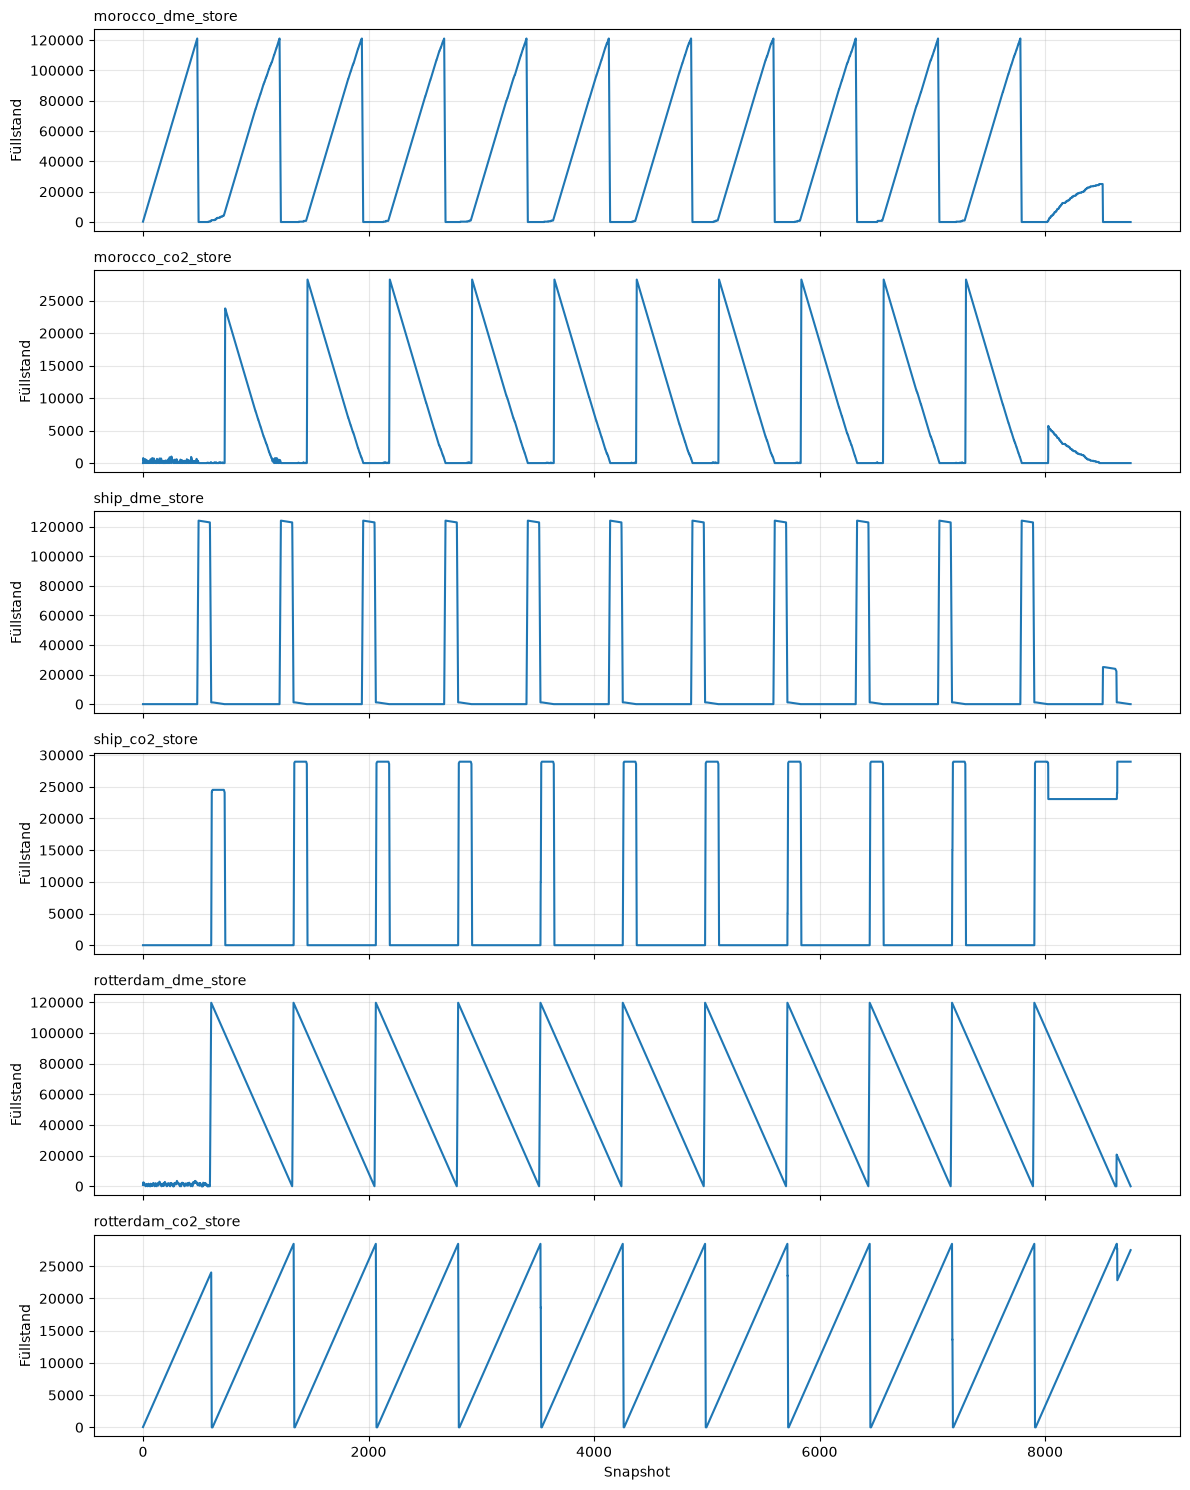

In [556]:
import matplotlib.pyplot as plt

stores = n.stores_t.e.copy()
fig, axes = plt.subplots(len(stores.columns), 1, figsize=(12, 2.5*len(stores.columns)), sharex=True)
for ax, col in zip(axes, stores.columns):
    ax.plot(stores.index, stores[col])
    ax.set_ylabel("Füllstand")
    ax.set_title(col, fontsize=10, loc="left")
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("Snapshot")
plt.tight_layout()
plt.show()

In [557]:
print("Zielfunktionswert:", n.objective)
print("\nOptimierte Speichergrößen (e_nom_opt):")
print(n.stores.e_nom_opt)
print("\nOptimierte Link-Leistungen (p_nom_opt):")
print(n.links.p_nom_opt)
print("\nFüllstand min/max je Store:")
print(n.stores_t.e.agg(["min", "max"]).T)
print("\nOptimierte Generatoren (p_nom_opt):")
print(n.generators.p_nom_opt)
print("CO2 welches komplett produziert werden muss:")
print(n.generators_t.p["co2_source"].sum())
print("DME welches am Anfang eingekauft werden muss in MWh:")
print(n.generators_t.p["rotterdam_init_dme_source"].sum())

Zielfunktionswert: 402688191.5013521

Optimierte Speichergrößen (e_nom_opt):
name
morocco_dme_store      121052.901484
morocco_co2_store       28247.545447
ship_dme_store         134682.170543
ship_co2_store          28956.666667
rotterdam_dme_store    119666.666667
rotterdam_co2_store     28480.666667
Name: e_nom_opt, dtype: float64

Optimierte Link-Leistungen (p_nom_opt):
name
morocco_dme_loading_link        10700.000000
morocco_co2_deloading_link       5000.000000
dme_generator                     295.467175
rotterdam_dme_deloading_link    10700.000000
rotterdam_co2_loading_link       5000.000000
hydrogen_generator                166.666667
Name: p_nom_opt, dtype: float64

Füllstand min/max je Store:
                              min            max
name                                            
morocco_dme_store   -0.000000e+00  121052.901484
morocco_co2_store   -0.000000e+00   28247.545447
ship_dme_store      -2.910383e-11  124066.666667
ship_co2_store      -0.000000e+00   28956.